C:\Users\VEDANT\AppData\Local\Temp\ipykernel_21464\333244316.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  4 of 4 completed
C:\Users\VEDANT\AppData\Local\Temp\ipykernel_21464\333244316.py:109: RuntimeWarning: divide by zero encountered in divide
  Dq = tau / (q_vals - 1)


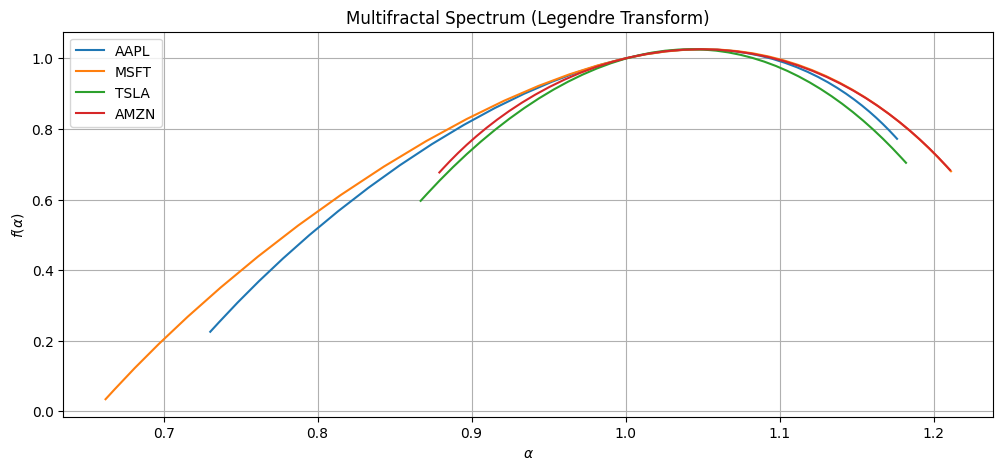

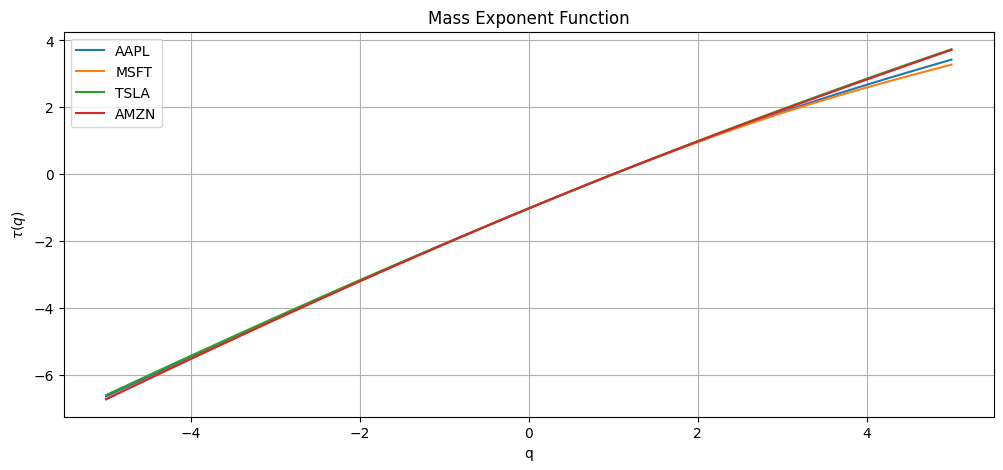

In [4]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# -------------------------------------------------------
# PARAMETERS
# -------------------------------------------------------
tickers = ["AAPL", "MSFT", "TSLA", "AMZN"]
start = "2018-01-01"
end = "2026-01-01"

q_vals = np.linspace(-5, 5, 41)
box_sizes = np.unique(np.logspace(1, 3, 20).astype(int))

# -------------------------------------------------------
# DOWNLOAD DATA
# -------------------------------------------------------
prices = yf.download(tickers, start=start, end=end)["Close"]
returns = np.abs(prices.pct_change().dropna())

# -------------------------------------------------------
# BOX MEASURE m(s,t)
# -------------------------------------------------------
def compute_measure(signal, box_size):
    N = len(signal)
    n_boxes = N // box_size
    m = np.zeros(n_boxes)

    for i in range(n_boxes):
        m[i] = np.sum(signal[i * box_size:(i + 1) * box_size])

    m /= np.sum(m)
    return m[m > 0]


# -------------------------------------------------------
# PARTITION FUNCTION χ(q,s)
# -------------------------------------------------------
def partition_function(signal, box_sizes, q_vals):
    chi = np.zeros((len(q_vals), len(box_sizes)))

    for i, s in enumerate(box_sizes):
        m = compute_measure(signal, s)

        for j, q in enumerate(q_vals):
            chi[j, i] = np.sum(m ** q)

    return chi


# -------------------------------------------------------
# MASS EXPONENT τ(q)
# -------------------------------------------------------
def compute_tau(chi, box_sizes):
    tau = []

    ln_s = np.log(box_sizes)

    for q_idx in range(chi.shape[0]):
        ln_chi = np.log(chi[q_idx])

        slope, _, _, _, _ = linregress(ln_s, ln_chi)
        tau.append(slope)

    return np.array(tau)


# -------------------------------------------------------
# CANONICAL (CHHABRA–JENSEN) METHOD
# -------------------------------------------------------
def canonical_spectrum(signal, box_sizes, q_vals):
    alpha = []
    f_alpha = []

    ln_s = np.log(box_sizes)

    for q in q_vals:
        A, F = [], []

        for s in box_sizes:
            m = compute_measure(signal, s)
            mu = m ** q
            mu /= np.sum(mu)

            A.append(np.sum(mu * np.log(m)))
            F.append(np.sum(mu * np.log(mu)))

        slope_a, _, _, _, _ = linregress(ln_s, A)
        slope_f, _, _, _, _ = linregress(ln_s, F)

        alpha.append(slope_a)
        f_alpha.append(slope_f)

    return np.array(alpha), np.array(f_alpha)


# -------------------------------------------------------
# MULTI-STOCK ANALYSIS
# -------------------------------------------------------
results = {}

for stock in tickers:
    signal = returns[stock].dropna().values

    chi = partition_function(signal, box_sizes, q_vals)
    tau = compute_tau(chi, box_sizes)
    Dq = tau / (q_vals - 1)

    alpha_leg = np.gradient(tau, q_vals)
    f_leg = q_vals * alpha_leg - tau

    alpha_can, f_can = canonical_spectrum(signal, box_sizes, q_vals)

    results[stock] = {
        "tau": tau,
        "Dq": Dq,
        "alpha_leg": alpha_leg,
        "f_leg": f_leg,
        "alpha_can": alpha_can,
        "f_can": f_can
    }

# -------------------------------------------------------
# PLOTS
# -------------------------------------------------------
plt.figure(figsize=(12, 5))

for stock in tickers:
    plt.plot(results[stock]["alpha_leg"],
             results[stock]["f_leg"], label=stock)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$f(\alpha)$")
plt.title("Multifractal Spectrum (Legendre Transform)")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(12, 5))
for stock in tickers:
    plt.plot(q_vals, results[stock]["tau"], label=stock)

plt.xlabel("q")
plt.ylabel(r"$\tau(q)$")
plt.title("Mass Exponent Function")
plt.legend()
plt.grid()
plt.show()


C:\Users\VEDANT\AppData\Local\Temp\ipykernel_21464\2504143700.py:20: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end)["Close"]
[*********************100%***********************]  9 of 9 completed


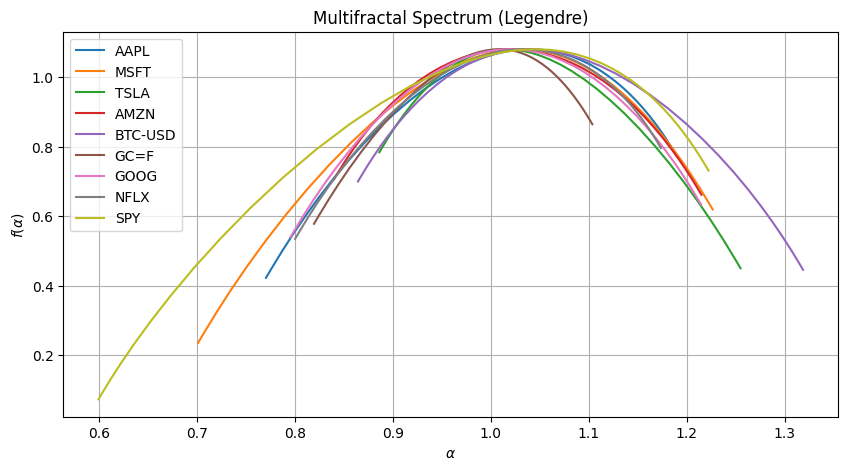

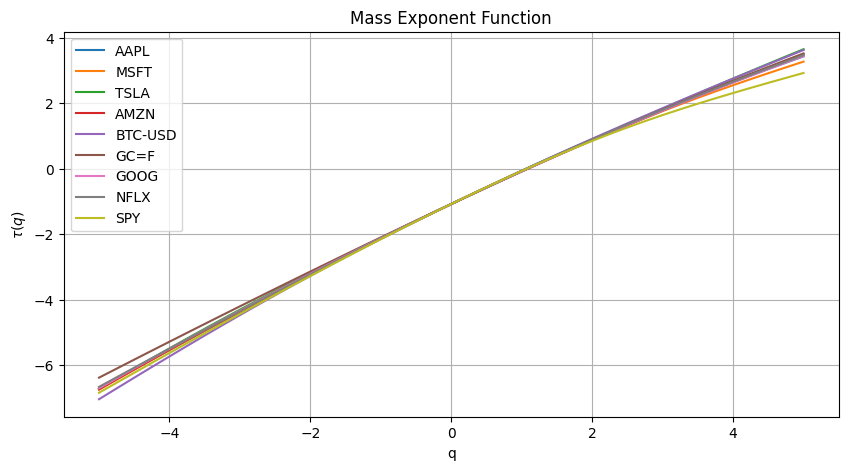

In [7]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# --------------------------------------------------
# PARAMETERS
# --------------------------------------------------
tickers = ["AAPL", "MSFT", "TSLA", "AMZN", "BTC-USD", "GC=F", "GOOG", "NFLX", "SPY"]
start = "2018-01-01"
end = "2025-01-01"

q_vals = np.linspace(-5, 5, 41)
box_sizes = np.unique(np.logspace(1, 3, 20).astype(int))

# --------------------------------------------------
# DOWNLOAD DATA
# --------------------------------------------------
prices = yf.download(tickers, start=start, end=end)["Close"]
returns = np.log(prices / prices.shift(1)).dropna()

# Absolute returns = volatility proxy
volatility = np.abs(returns)

def probability_density(signal):
    u = np.abs(signal)
    return u / np.sum(u)

def box_measure(u, s):
    N = len(u)
    n_boxes = N // s
    m = np.zeros(n_boxes)

    for i in range(n_boxes):
        m[i] = np.sum(u[i*s:(i+1)*s])

    return m[m > 0]

def partition_function(u, box_sizes, q_vals):
    chi = np.zeros((len(q_vals), len(box_sizes)))

    for i, s in enumerate(box_sizes):
        m = box_measure(u, s)

        for j, q in enumerate(q_vals):
            chi[j, i] = np.sum(m**q)

    return chi

def compute_tau(chi, box_sizes):
    ln_s = np.log(box_sizes)
    tau = np.zeros(chi.shape[0])

    for i in range(chi.shape[0]):
        slope, _, _, _, _ = linregress(ln_s, np.log(chi[i]))
        tau[i] = slope

    return tau

def generalized_dimensions(tau, q_vals):
    Dq = np.zeros_like(tau)
    mask = q_vals != 1
    Dq[mask] = tau[mask] / (q_vals[mask] - 1)
    return Dq

def legendre_spectrum(tau, q_vals):
    alpha = np.gradient(tau, q_vals)
    f_alpha = q_vals * alpha - tau
    return alpha, f_alpha

def canonical_spectrum(u, box_sizes, q_vals):
    ln_s = np.log(box_sizes)
    alpha, f_alpha = [], []

    for q in q_vals:
        A, F = [], []

        for s in box_sizes:
            m = box_measure(u, s)
            mu = m**q
            mu /= np.sum(mu)

            A.append(np.sum(mu * np.log(m)))
            F.append(np.sum(mu * np.log(mu)))

        a_slope, _, _, _, _ = linregress(ln_s, A)
        f_slope, _, _, _, _ = linregress(ln_s, F)

        alpha.append(a_slope)
        f_alpha.append(f_slope)

    return np.array(alpha), np.array(f_alpha)

def inverse_partition_function(u, p_vals, mu_vals):
    U = np.cumsum(u)
    T = len(u)
    tau_inv = []

    for p in p_vals:
        chi = []

        for mu in mu_vals:
            J = int(1 / mu)
            s = []

            for j in range(1, J+1):
                idx = np.searchsorted(U, j * mu)
                s.append(idx / T)

            chi.append(np.sum(np.array(s)**p))

        slope, _, _, _, _ = linregress(np.log(mu_vals), np.log(chi))
        tau_inv.append(slope)

    return np.array(tau_inv)

results = {}

for stock in tickers:
    u = probability_density(volatility[stock].dropna().values)

    chi = partition_function(u, box_sizes, q_vals)
    tau = compute_tau(chi, box_sizes)
    Dq = generalized_dimensions(tau, q_vals)

    alpha_leg, f_leg = legendre_spectrum(tau, q_vals)
    alpha_can, f_can = canonical_spectrum(u, box_sizes, q_vals)

    results[stock] = {
        "tau": tau,
        "Dq": Dq,
        "alpha_leg": alpha_leg,
        "f_leg": f_leg,
        "alpha_can": alpha_can,
        "f_can": f_can
    }

plt.figure(figsize=(10,5))
for stock in tickers:
    plt.plot(results[stock]["alpha_leg"],
             results[stock]["f_leg"], label=stock)

plt.xlabel(r"$\alpha$")
plt.ylabel(r"$f(\alpha)$")
plt.title("Multifractal Spectrum (Legendre)")
plt.legend()
plt.grid()
plt.show()

plt.figure(figsize=(10,5))
for stock in tickers:
    plt.plot(q_vals, results[stock]["tau"], label=stock)

plt.xlabel("q")
plt.ylabel(r"$\tau(q)$")
plt.title("Mass Exponent Function")
plt.legend()
plt.grid()
plt.show()



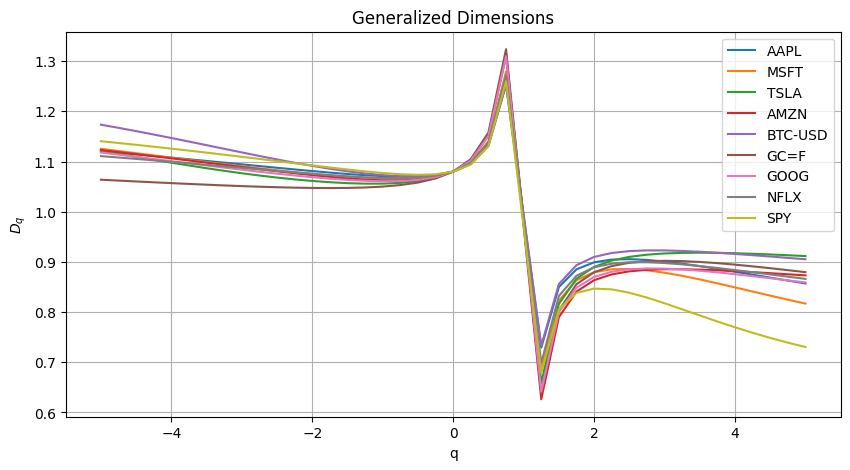

In [10]:
plt.figure(figsize=(10,5))
for stock in tickers:
    Dq = results[stock]["Dq"]
    mask = q_vals != 1
    plt.plot(q_vals[mask], Dq[mask], label=stock)

plt.xlabel("q")
plt.ylabel(r"$D_q$")
plt.title("Generalized Dimensions")
plt.legend()
plt.grid()
plt.show()


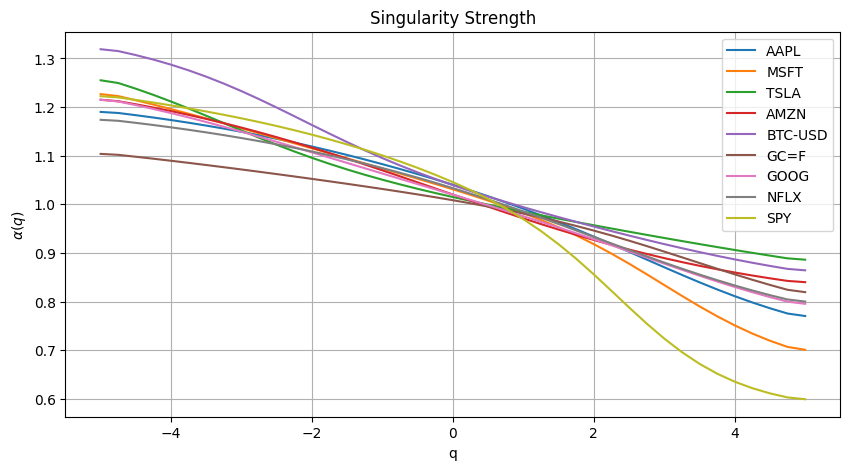

In [11]:
plt.figure(figsize=(10,5))
for stock in tickers:
    plt.plot(q_vals, results[stock]["alpha_leg"], label=stock)

plt.xlabel("q")
plt.ylabel(r"$\alpha(q)$")
plt.title("Singularity Strength")
plt.legend()
plt.grid()
plt.show()


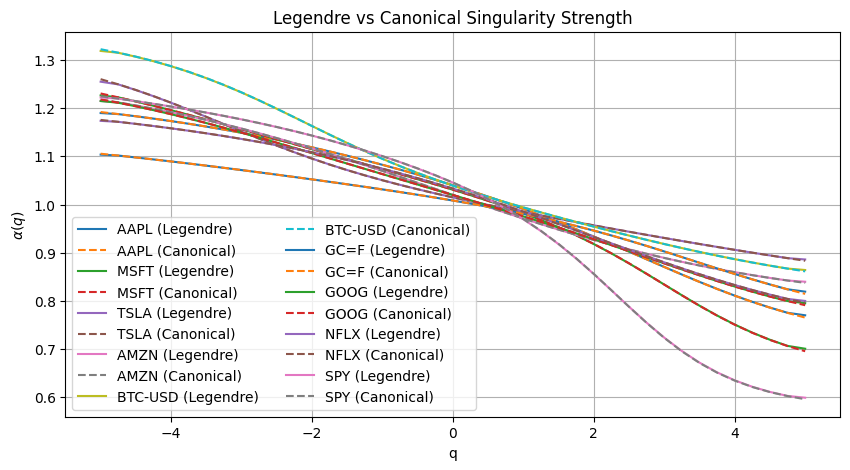

In [12]:
plt.figure(figsize=(10,5))
for stock in tickers:
    plt.plot(q_vals, results[stock]["alpha_leg"],
             label=f"{stock} (Legendre)")
    plt.plot(q_vals, results[stock]["alpha_can"],
             "--", label=f"{stock} (Canonical)")

plt.xlabel("q")
plt.ylabel(r"$\alpha(q)$")
plt.title("Legendre vs Canonical Singularity Strength")
plt.legend(ncol=2)
plt.grid()
plt.show()


In [13]:
print("Spectrum width Δα:")
for stock in tickers:
    alpha = results[stock]["alpha_leg"]
    width = alpha.max() - alpha.min()
    print(f"{stock:8s}  Δα = {width:.4f}")


Spectrum width Δα:
AAPL      Δα = 0.4198
MSFT      Δα = 0.5259
TSLA      Δα = 0.3690
AMZN      Δα = 0.3753
BTC-USD   Δα = 0.4548
GC=F      Δα = 0.2844
GOOG      Δα = 0.4197
NFLX      Δα = 0.3739
SPY       Δα = 0.6233


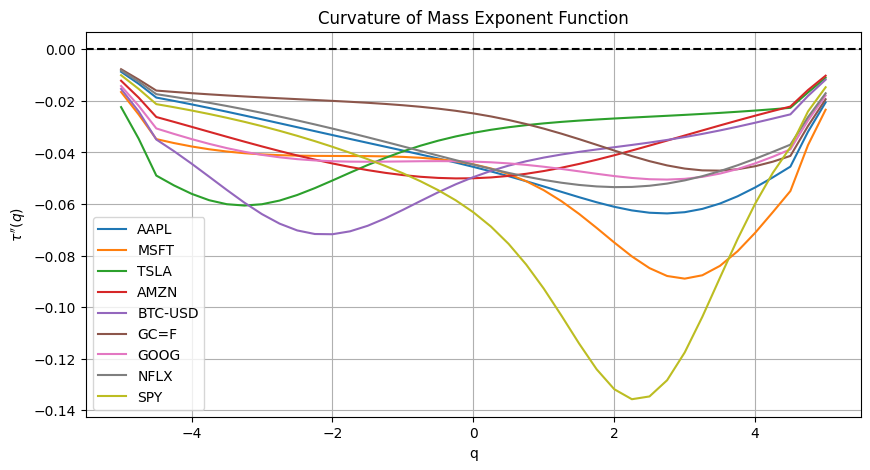

In [14]:
plt.figure(figsize=(10,5))
for stock in tickers:
    tau = results[stock]["tau"]
    curvature = np.gradient(np.gradient(tau, q_vals), q_vals)
    plt.plot(q_vals, curvature, label=stock)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("q")
plt.ylabel(r"$\tau''(q)$")
plt.title("Curvature of Mass Exponent Function")
plt.legend()
plt.grid()
plt.show()


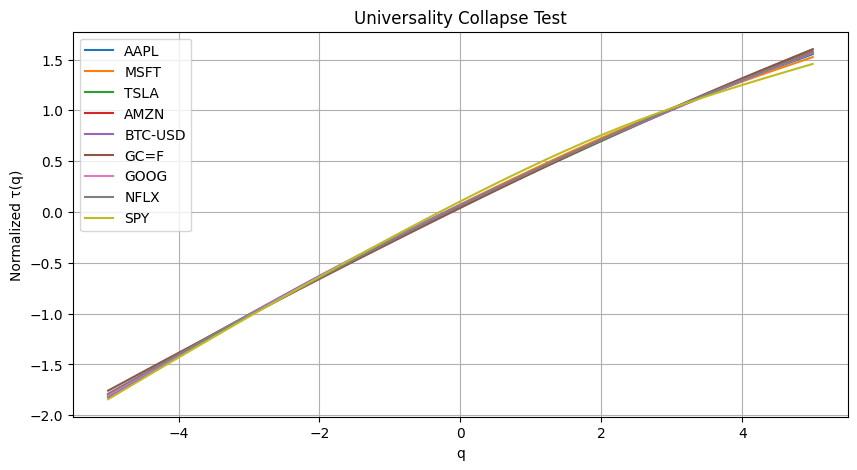

In [15]:
plt.figure(figsize=(10,5))
for stock in tickers:
    tau = results[stock]["tau"]
    tau_norm = (tau - tau.mean()) / tau.std()
    plt.plot(q_vals, tau_norm, label=stock)

plt.xlabel("q")
plt.ylabel("Normalized τ(q)")
plt.title("Universality Collapse Test")
plt.legend()
plt.grid()
plt.show()
